In [1]:
import torch
from torch import nn

class MatrixFactorization(nn.Module):
    def __init__(self, n_users, n_movies, dim, global_mean):
        super().__init__()

        # user vectors
        self.user_vectors = nn.Embedding(n_users, dim)

        # movie vectors
        self.movie_vectors = nn.Embedding(n_movies, dim)

        # user biases
        self.user_biases = nn.Embedding(n_users, 1)
        
        # movie biases 
        self.movie_biases = nn.Embedding(n_movies, 1)

        self.global_mean = global_mean

        nn.init.normal_(self.user_vectors.weight, std=0.01)
        nn.init.normal_(self.movie_vectors.weight, std=0.01)
        nn.init.zeros_(self.user_biases.weight)
        nn.init.zeros_(self.movie_biases.weight)

    def forward(self, user_idx, movie_idx):
        u = self.user_vectors(user_idx)
        m = self.movie_vectors(movie_idx)

        dot = (u * m).sum(dim = 1)

        bu = self.user_biases(user_idx).squeeze(1)
        bm = self.movie_biases(movie_idx).squeeze(1)

        return self.global_mean + bu + bm + dot




In [2]:
# Load the Data
import pandas as pd

DATA = "../data/processed/ml-latest-small"
train = pd.read_csv(DATA + "/train.csv")

train_users = torch.tensor(train['user_idx'].values)
train_movies = torch.tensor(train['movie_idx'].values)
train_ratings = torch.tensor(train['rating'].values)

val = pd.read_csv(DATA + "/val.csv")

val_users = torch.tensor(val['user_idx'].values)
val_movies = torch.tensor(val['movie_idx'].values)
val_ratings = torch.tensor(val['rating'].values)

In [3]:
n_users = train['user_idx'].max() + 1
n_movies = train['movie_idx'].max() + 1
global_mean = train['rating'].mean()

# model = MatrixFactorization(n_users, n_movies, 50, global_mean)
# optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-5)

Training Hyper parameters

In [ ]:
BATCH_SIZE = 1024
n = len(train_ratings)

# CHANGED: added the patience argument (how many epochs without improvement before stopping)
def train_model(dim, lr, weight_decay, epochs=1000, patience=10):
    torch.manual_seed(0)
    model = MatrixFactorization(n_users, n_movies, dim, global_mean)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val = float("inf")
    best_epoch = 0

    for epoch in range(epochs):
        order = torch.randperm(n)
        for start in range(0, n, BATCH_SIZE):
                idx = order[start:start + BATCH_SIZE]
        
                pred = model(train_users[idx], train_movies[idx])
                loss = ((pred - train_ratings[idx]) ** 2).mean()
        
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        
                #epoch_loss += loss.item()
                #n_batches += 1
        
        with torch.no_grad():
            val_pred = model(val_users, val_movies)
            val_mse = ((val_pred - val_ratings) ** 2).mean()

        if val_mse.item() < best_val:
            best_val = val_mse.item()
            best_epoch = epoch + 1
        # ADDED: stop once validation has gone `patience` epochs without a new best
        elif epoch + 1 - best_epoch >= patience:
            break

    return best_val, best_epoch, model

In [ ]:
LRS = [0.0003, 0.001, 0.003]
DIMS = [16, 32, 64, 128]
WEIGHT_DECAYS = [1e-7, 1e-6, 1e-5, 1e-4]

runs = []
for lr in LRS:
    for dim in DIMS:
        for wd in WEIGHT_DECAYS:
            best_val, best_epoch, _ = train_model(dim=dim, lr=lr, weight_decay=wd)
            runs.append({"lr": lr, "dim": dim, "weight_decay": wd,
                         "best_val": best_val, "best_epoch": best_epoch})
            print(lr, dim, wd, round(best_val, 4), best_epoch)

best = min(runs, key=lambda r: r["best_val"])
print(best)


final_val, _, best_model = train_model(dim=best["dim"], lr=best["lr"],
                                       weight_decay=best["weight_decay"],
                                       epochs=best["best_epoch"])
print("best_model validation MSE:", final_val)

0.0003 32 1e-07 0.6469 81
0.0003 32 1e-06 0.6473 81
0.0003 32 1e-05 0.6479 84
0.0003 32 0.0001 0.6508 97
0.0003 64 1e-07 0.6675 53
0.0003 64 1e-06 0.6673 53
0.0003 64 1e-05 0.6657 58
0.0003 64 0.0001 0.6632 67
0.0003 128 1e-07 0.6755 44
0.0003 128 1e-06 0.6755 44
0.0003 128 1e-05 0.6752 44
0.0003 128 0.0001 0.6717 59
0.0003 256 1e-07 0.6854 28
0.0003 256 1e-06 0.6851 28
0.0003 256 1e-05 0.6843 28
0.0003 256 0.0001 0.6839 34
0.001 32 1e-07 0.6477 23
0.001 32 1e-06 0.6495 23
0.001 32 1e-05 0.6537 24
0.001 32 0.0001 0.6557 29
0.001 64 1e-07 0.6783 15
0.001 64 1e-06 0.6779 15
0.001 64 1e-05 0.6754 15
0.001 64 0.0001 0.6692 21
0.001 128 1e-07 0.6826 11
0.001 128 1e-06 0.6824 11
0.001 128 1e-05 0.682 11
0.001 128 0.0001 0.6756 16
0.001 256 1e-07 0.6886 9
0.001 256 1e-06 0.6876 9
0.001 256 1e-05 0.686 9
0.001 256 0.0001 0.6833 9
0.003 32 1e-07 0.6607 8
0.003 32 1e-06 0.6634 8
0.003 32 1e-05 0.6685 8
0.003 32 0.0001 0.6636 9
0.003 64 1e-07 0.6779 5
0.003 64 1e-06 0.6748 5
0.003 64 1e-05 0.6688

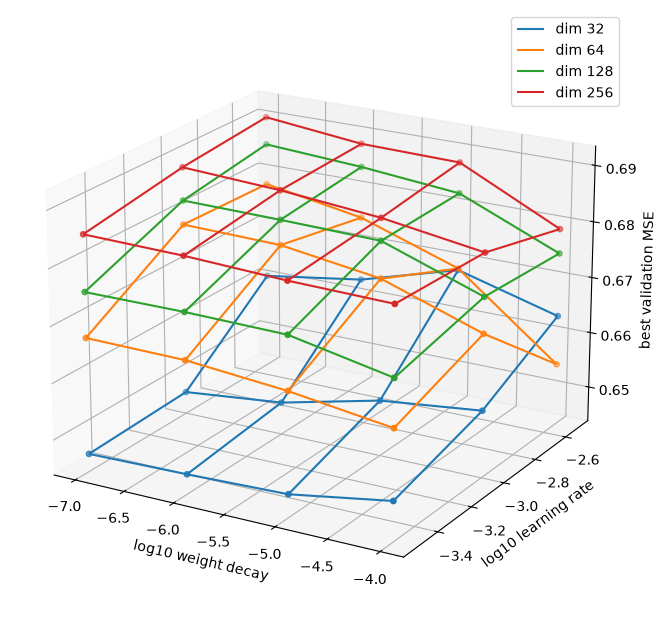

In [6]:
import numpy as np
import matplotlib.pyplot as plt

X, Y = np.meshgrid(np.log10(WEIGHT_DECAYS), np.log10(LRS))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")

for dim, color in zip(DIMS, plt.cm.tab10.colors):
    # error for this vector size, as a grid: rows are learning rates, columns are weight decays
    Z = np.array([[next(r["best_val"] for r in runs
                        if r["dim"] == dim and r["lr"] == lr and r["weight_decay"] == wd)
                   for wd in WEIGHT_DECAYS] for lr in LRS])
    ax.plot_wireframe(X, Y, Z, color=color, label=f"dim {dim}")
    ax.scatter(X, Y, Z, color=color, s=15)

ax.set_xlabel("log10 weight decay")
ax.set_ylabel("log10 learning rate")
ax.set_zlabel("best validation MSE")
ax.legend()
ax.view_init(elev=20, azim=-60)
plt.show()

Final model

In [ ]:
import copy

DIM = 32
LR = 0.001
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 100
PATIENCE = 5

torch.manual_seed(0)
final_model = MatrixFactorization(n_users, n_movies, DIM, global_mean)
optimizer = torch.optim.Adam(final_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

train_history = []
val_history = []
best_val = float("inf")
best_epoch = 0

for epoch in range(MAX_EPOCHS):
    order = torch.randperm(n)
    epoch_loss = 0.0
    n_batches = 0

    for start in range(0, n, BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]

        pred = final_model(train_users[idx], train_movies[idx])
        loss = ((pred - train_ratings[idx]) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    with torch.no_grad():
        val_pred = final_model(val_users, val_movies)
        val_mse = ((val_pred - val_ratings) ** 2).mean()
    
    train_history.append(epoch_loss / n_batches)
    val_history.append(val_mse.item())
    print(epoch + 1, round(train_history[-1], 4), round(val_history[-1], 4))

    if val_mse.item() < best_val:
        best_val = val_mse.item()
        best_epoch = epoch + 1
        best_state = copy.deepcopy(final_model.state_dict())
    elif epoch + 1 - best_epoch >= PATIENCE:
        break


final_model.load_state_dict(best_state)
print("best validation MSE:", best_val, "at epoch", best_epoch)

1 0.966 1.1024
2 0.9256 1.0611
3 0.8617 0.99
4 0.7736 0.9135
5 0.6994 0.8529
6 0.6517 0.81
7 0.6195 0.7825
8 0.5969 0.7589
9 0.5775 0.7406
10 0.5594 0.7268
11 0.5433 0.7147
12 0.5273 0.7044
13 0.511 0.6969
14 0.4946 0.6877
15 0.4784 0.6811
16 0.4623 0.6748
17 0.4466 0.67
18 0.4309 0.6654
19 0.4158 0.662
20 0.4009 0.6587
21 0.3867 0.6561
22 0.3735 0.6547
23 0.3598 0.654
24 0.3473 0.6537
25 0.3352 0.6544
26 0.3235 0.6552
27 0.3121 0.6569
28 0.3017 0.6594
29 0.2914 0.6611
best validation MSE: 0.6537192491455023 at epoch 24


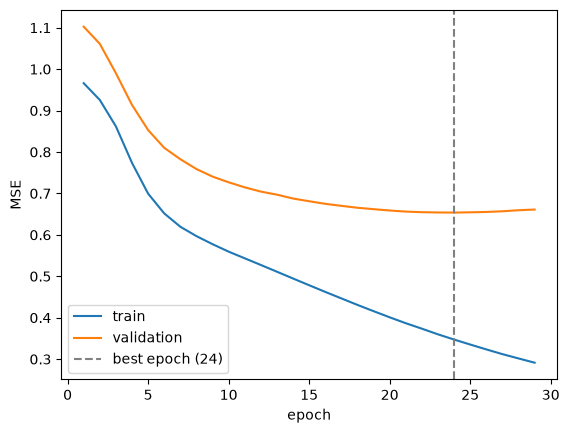

In [8]:
import matplotlib.pyplot as plt

epochs_run = range(1, len(train_history) + 1)

plt.plot(epochs_run, train_history, label="train")
plt.plot(epochs_run, val_history, label="validation")
# dashed line marks the epoch final_model was restored to
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [9]:
MODEL_PATH = "../models/mf_small.pt"
torch.save(final_model.state_dict(), MODEL_PATH)
print("saved to", MODEL_PATH)

saved to ../models/mf_small.pt
